# Содержание

1. [Загрузка данных](#s1)

2. [Класс ModelPipeline](#s2)

3. [Обучение и оценка моделей](#s3)
     
4. [Проверка лучшей модели](#s4)

5. [Вывод](#s5)

<div style="border:solid purple 5px; padding: 20px"> 


<b>Цель проекта</b>

<hr>
Создать систему раннего оповещения о развитии аварийных режимов водно-химического режима котла, основанную на анализе многомерных временных рядов с дифференциацией типов уноса для выбора корректной корректирующей стратегии.

<hr>
    
В данной тетради проводится  <b> подбор гиперпараметров и сравнение моделей (RandomForest, XGB, CatBoost), тестирование лучшей модели. </b>

**df_train.csv** - датасет для обучения моделей. 

**df_test.csv** - датасет для проверки лучшей модели
       
<hr>

</div>  

Тип уноса:

- 0: 'Кислый унос (хлоридный)' 
- 1: 'Натриевый унос (щелочной)' 
- 2: 'Норма' 
- 3: 'Переходный режим'

In [1]:
#!pip install xgboost

In [2]:
#!pip install catboost

In [3]:
#!pip install pandas==2.2.3

In [4]:
#!pip install numpy==2.1.3

In [5]:
#!pip install matplotlib

In [6]:
#!pip install seaborn

In [7]:
#!python -m pip install scikit-learn

In [8]:
#!pip install tqdm

In [9]:
#!pip install tabulate

In [10]:
import warnings
warnings.filterwarnings('ignore')

In [11]:
import time

In [12]:
import pandas as pd
import numpy as np

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

In [14]:
from sklearn.base import clone

In [15]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

In [16]:
from tabulate import tabulate

In [17]:
import textwrap

In [18]:
from sklearn.model_selection import StratifiedGroupKFold

In [19]:
from sklearn.compose import ColumnTransformer
#from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.dummy import DummyClassifier
#from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight

In [20]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [21]:
from sklearn.model_selection import GridSearchCV

In [22]:
from sklearn.model_selection import RandomizedSearchCV
from tqdm import tqdm

In [23]:
from sklearn.preprocessing import label_binarize

In [24]:
from pathlib import Path

In [25]:
data_dir =  Path('../data')
note_dir = Path('../notebooks')
figures_dir = Path('../reports/figures')
tables_dir = Path('../reports/tables')

## <a id="s1"></a> 1. Загрузка данных

In [26]:
train = pd.read_csv(data_dir/'df_train.csv', index_col ='data_time', parse_dates=[0])
test = pd.read_csv(data_dir/'df_test.csv', index_col ='data_time', parse_dates=[0])

In [27]:
train.head(2)

,hal40cf001,lba10cq201,had10cl001,hah90ct001,hha10cp001,had10cp001,lba10cf001,lba08cp001,hour_sin,hour_cos,dow_sin,dow_cos,lba10cq201_mean_2h,lba10cq201_std_2h,lba10cq201_std_4h,lba10cq201_delta_1,lba10cq201_delta_2,lba10cq201_delta_3,lba10cq201__accel,unos_type,group_id
data_time,,,,,,,,,,,,,,,,,,,,,
2017-01-01 07:00:00,0.528895,9.179148,-9.612786,521.836548,-4.428509,104.340546,174.140381,96.984283,0.965926,-0.258819,-0.781831,0.62349,9.261284,0.026110,0.042371,-0.100598,-0.063673,-0.000073,-0.137523,2,1
2017-01-01 08:00:00,0.503179,9.119442,-9.361613,523.308228,-4.457798,104.853897,173.366608,97.536438,0.866025,-0.500000,-0.781831,0.62349,9.229447,0.071133,0.049739,-0.059706,-0.160304,-0.123379,0.040892,2,1


In [28]:
features = train.copy()
features.drop(['group_id','unos_type'], axis=1, inplace=True)
target = train['unos_type']
groups = train['group_id']

In [29]:
features_test = test.copy()
target_test = test['unos_type']
features_test.drop(['group_id','unos_type'], axis=1, inplace=True)

Прежде чем проводить тестирование моделей, необходимо подобрать отимальные гиперпараметры, т.к. модели на дефолтных значениях могут проигрывать. Для оптимизации ресурсов проведем подбор гиперпараметров на первом фолде (без валидационной части) и сравнним модели с лучшими гиперпораметрами на 5 фолдах.

## <a id="s2"></a> 2. Класс ModelPipeline

In [30]:
#My code2
class ModelPipeline:
    def __init__(self, X_train, y_train, groups, n_splits=5, random_state=12345):
        self.feature = X_train
        self.target = y_train
        self.groups = groups
        self.random_state = random_state

        out_cv = StratifiedGroupKFold(n_splits=n_splits)
        self.splits = list(out_cv.split(X_train, y_train, groups=groups))
        
        self.classes = np.unique(y_train)
        self.class_names = ['0: Кислый унос', '1: Натриевый унос', '2: Норма', '3: Переходный режим']
        
        self.models = {}
        self.screening_params = {}     # этап 1
        self.cv_results = {}           # этап 2
        self.best_model_name = None
        self.tuned_params = None       # этап 3
        self.final_model = None
        self.test_metrics = None

    def add_model(self, name, estimator, param_dist=None, need_sample_weight=False):
        """ Функция регистрации модели """
        
        self.models[name] = {
           'estimator':estimator,
           'param_dist':param_dist or {},
           'need_sample_weight':need_sample_weight
       }
        self.cv_results[name] = {'folds':[], 'mean':[], 'std':[]}

    def _fit_kwargs(self, y):
        sw = compute_sample_weight(class_weight='balanced', y=y)
        return {'sample_weight' : sw}

    def _info_cv(self, splitter, feature_train, target_train, groups_train, file_name='cv_info'):
        """ Функция информирует о группах на которых обучаются и тестируются модели """
        rows = []
        for in_fold, (train_idx, valid_idx) in enumerate(splitter):
            print(f"\nFold {in_fold+1}")
            train_groups_in = np.unique(groups_train.iloc[train_idx])
            valid_groups_in   = np.unique(groups_train.iloc[valid_idx])
        
            count_train_classes_in = target_train.iloc[train_idx].nunique()
            count_valid_classes_in   = target_train.iloc[valid_idx].nunique()
            print(f" Кол-во классов на обучении/валидации: {count_train_classes_in}/{count_valid_classes_in}")
            print(f" Группы на обучении: {train_groups_in.tolist()}")
            print(f" Группы на валидации: {valid_groups_in.tolist()}")
            
            rows.append({
            'fold': in_fold + 1,
            'n_train_classes': count_train_classes_in,
            'n_valid_classes': count_valid_classes_in,
            'train_groups': train_groups_in.tolist(),
            'valid_groups': valid_groups_in.tolist(),
            })
        df = pd.DataFrame(rows)
        file_name = f"{file_name}.md"
        df.to_markdown(tables_dir/file_name, index=False)

        print(f"{'='*50}")
        return df
    
    def _add_savefig(self, name_plot):
        filename = f"{name_plot}.png"
        plt.savefig(figures_dir/filename , dpi=150, bbox_inches='tight')
    
    def _plot_roc_curves(self, name, y_true, proba_oof, save_plot = True, name_plot='roc_curves'): 
        """
        Построение ROC-кривых для каждого класса
        """
        plt.figure(figsize=(6, 4))
        target_bin = label_binarize(y_true, classes=self.classes)
        for i in range(len(self.classes)):
            fpr, tpr, _ = roc_curve(target_bin[:, i], proba_oof[:, i]) 
            roc_auc_value = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f'Класс {i} (AUC = {roc_auc_value:.3f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Случайный классификатор (AUC = 0.5)')

        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC-кривые для каждого класса ({name})')
        plt.legend(loc="lower right")
        plt.grid(True, alpha=0.3)
        if save_plot:
            filename = f"{name}_{name_plot}"
            self._add_savefig(filename)
        plt.show()

    def _plot_confusion_matrix(self, name, y_true, y_pred, save_plot = True, name_plot='confusion_matrix'):
        """
        Построение матрицы ошибок
        """
        plt.figure(figsize=(6, 5))
        cm = confusion_matrix(y_true, y_pred, labels=self.classes)

        n_classes = len(self.classes)
        labels = self.class_names[:n_classes]

        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues',
            yticklabels=labels,   # истинные классы
            xticklabels=labels,   # предсказанные классы
            cbar_kws={'shrink': 0.8},
        )
        plt.xlabel('Предсказанный класс')
        plt.ylabel('Истинный класс')
        plt.title(f'Confusion Matrix - {name}')
        plt.tight_layout()
        if save_plot:
            filename = f'{name}_{name_plot}'
            self._add_savefig(filename)
        plt.show()
    
    def _print_search_result(self, search, name, top_n=10):
        """ Функция выводит данные при настройке гиперпараметров модели """
        
        results = pd.DataFrame(search.cv_results_)          
        results['gap'] = results['mean_train_score'] - results['mean_test_score']
        cols = ['params', 'mean_train_score', 'mean_test_score',
                               'std_train_score', 'std_test_score', 'gap', 'rank_test_score']
        top = results.sort_values('mean_test_score', ascending=False).head(top_n)[cols]
        for c in ['mean_train_score', 'mean_test_score', 'std_train_score', 'std_test_score', 'gap']:
            top[c] = top[c].round(4)
        top['params'] = top['params'].apply(
        lambda p: ', '.join(f'{k}={v}' for k, v in sorted(p.items()))
        )
        top = top.rename(columns={
        'mean_train_score': 'train',
        'mean_test_score':  'val',
        'std_train_score':  'std_tr',
        'std_test_score':   'std_v',
        'rank_test_score':  'rank',
        })
        top['params'] = top['params'].apply(lambda s: '\n'.join(textwrap.wrap(s, 80)))
        #Переносим  params по строкам внутри ячейки
        print(tabulate(top, headers='keys', tablefmt='grid', showindex=False,
                       maxcolwidths=[80] + [None] * (len(top.columns) - 1),
                      ))
        filename = f'search_results_{name}.csv'
        results.to_csv(tables_dir/filename, index=False)

        
    def _top_coef_trees(self, name, model, features, top=10):
        """ Вывод важные признаки """
        
        feature_importance = pd.DataFrame({
            'feature': features.columns,
            'importance': model.feature_importances_  # importance
            }).sort_values('importance', ascending=False)
        
        print(f"\nТоп-{top} важнейших признаков для {name}:")
        print(feature_importance.head(top))
        filename = f'top_features_{name}.csv'
        feature_importance.to_csv(tables_dir/filename, index=False, encoding='utf-8-sig')
        #return top_coef.to_list()
    
    def screen_models(self, n_iter=10, scoring='f1_macro', splitter='first_fold', verbose=True):
        """ Функция подбирает гиперпараметры моделей на первом фолде
       или на конкретных группах. Запоминает лучшие гиперпараметры """
        
        if splitter == 'first_fold':
            train_idx, valid_idx = self.splits[0]
        elif splitter == 'custom':
            groups_for_train = [1, 3, 5, 7, 9] 
            train_idx = np.where(self.groups.isin(groups_for_train).to_numpy())[0]         
        else:
            raise ValueError(
                f"Unknown splitter: {splitter}"
                f"Expected one of: 'first_fold', 'custom'."
            )
        
        feature_train = self.feature.iloc[train_idx]
        target_train = self.target.iloc[train_idx]
        groups_train = self.groups.iloc[train_idx]    

        count_train_classes = target_train.nunique()
           
        can_search = (count_train_classes == len(self.classes))
        if not can_search:
            raise print(
                f"Количество классов: {count_train_classes}"
                f"Подбор гиперпараметров моделей может быть не оптимальный."
                f"Выберите режим 'custom' или используйте другой датасет."
            )                        
        
        print(f"Начинаю поиск параметров для модели...")
        in_cv = StratifiedGroupKFold(n_splits=3)  
        in_splits = list(in_cv.split(feature_train, target_train, groups_train))
        
        if verbose:
            print(f'Подбор гиперпараметров будет проведено на данных:')
            file_name = 'cv_info_hyperparameter_tuning'
            self._info_cv(in_splits, feature_train, target_train, groups_train, file_name)     
        
        for name, info in self.models.items():
            print(f"\n{'='*50}\nСкриннинг: {name}\n{'='*50}")
            if not info['param_dist']:
                self.screening_params[name] = {}
                if verbose:
                    print("  param_dist пуст — используем дефолт")
                continue
        
            search = RandomizedSearchCV(
                estimator=clone(info['estimator']),
                param_distributions=info['param_dist'],
                n_iter=n_iter,
                scoring=scoring,
                cv=in_cv,
                n_jobs=-1,
                random_state=self.random_state,
                return_train_score=True,
                verbose=0,
                )
            fit_kwargs = self._fit_kwargs(target_train) if info['need_sample_weight'] else {}
            with tqdm(total=1, desc="  Поиск параметров", unit="процесс") as pbar:
                search.fit(feature_train, target_train, groups=groups_train, **fit_kwargs)
                pbar.update(1)
            self.screening_params[name] = search.best_params_
        
            if verbose:
                print(f"  Параметры: {search.best_params_}")
                print(f"  score ({scoring}): {search.best_score_:.4f}")
                self._print_search_result(search, name, top_n=10)
                
        print(f"{'='*50}")
        return self.screening_params

    def _metrics(self, y_true, y_pred, y_proba):
        """ Метрики  """
        
        f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
        f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)
        if y_proba is not None:
            y_bin = label_binarize(y_true, classes=self.classes)
            roc = roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr')
        else:
            roc = None
   
        return  {'f1_macro': f1_macro, 'f1_weighted': f1_weighted, 'roc_auc_ovr': roc}

    def cross_validate(self, metric='f1_macro', verbose=True, plot_roc=True, plot_cm=True):
        """ Тестирование моделей с лучшими параметрами с помощью кросс-валидации"""
        
        if verbose:
            print(f'Сравнение моделей будет проведено на данных:')
            file_name = "cv_info_cross_validate"
            self._info_cv(self.splits, self.feature, self.target, self.groups, file_name)    
        for name, info in self.models.items():
            if verbose:
                print(f"\n{'='*60}\nCV: {name}\n{'='*60}")                
            params = self.screening_params.get(name, {})

            n = len(self.target)
            n_classes = len(self.classes)
            
            oof_pred  = np.empty(n, dtype=self.target.dtype) #out-of-fold pred
            oof_proba = np.full((n, n_classes), np.nan) #out-of-fold proba
            
            for fold_idx, (train_idx, valid_idx) in enumerate(self.splits):
                feature_train = self.feature.iloc[train_idx]
                feature_valid = self.feature.iloc[valid_idx]
                target_train = self.target.iloc[train_idx]
                target_valid = self.target.iloc[valid_idx] 
                
                model = clone(info['estimator']).set_params(**params)
                fit_kwargs = self._fit_kwargs(target_train) if info['need_sample_weight'] else {}
                model.fit(feature_train, target_train, **fit_kwargs )

                pred_valid = model.predict(feature_valid)
                oof_pred[valid_idx] = pred_valid.reshape(-1)
                
                proba_valid = None
                if hasattr(model, 'predict_proba'):
                    proba_valid = model.predict_proba(feature_valid)              
                    oof_proba[valid_idx, :] = np.asarray(proba_valid)

                m = self._metrics(target_valid, pred_valid, proba_valid)                
                m['fold'] = fold_idx + 1
                m['model'] = name
                self.cv_results[name]['folds'].append(m)
                
                if verbose:
                    print(f"  Fold {fold_idx+1}: "
                          f"f1_macro={m['f1_macro']:.4f} "
                          f"f1_weighted={m['f1_weighted']:.4f} "
                          f"roc_auc_ovr={m['roc_auc_ovr']:.4f}")
            folds_df = pd.DataFrame(self.cv_results[name]['folds'])
            metric_cols = [c for c in folds_df.columns if c not in ('fold', 'model')]
            folds_df = folds_df[['model', 'fold'] + metric_cols].round(4)
            file_name = f'score_{name}.md'.replace('/', '_').replace(' ', '_')
            folds_df.to_markdown(tables_dir / file_name, index=False)

        if verbose:
            print(f"  → метрики сохранены: {tables_dir / file_name}")
            
            self.cv_results[name]['oof_pred']  = oof_pred
            self.cv_results[name]['oof_proba'] = oof_proba      
            keys = ['f1_macro', 'f1_weighted', 'roc_auc_ovr']
            folds = self.cv_results[name]['folds']
            self.cv_results[name]['mean'] = {
                k: float(np.mean([f[k] for f in folds])) for k in keys
            }
            self.cv_results[name]['std'] = {
                k: float(np.std([f[k] for f in folds])) for k in keys
            }

            if plot_roc and not np.isnan(oof_proba).any():
                name_plot = 'roc_curves_oof'
                self._plot_roc_curves(name, self.target.values, oof_proba, save_plot = True, name_plot=name_plot)
            if plot_cm:
                name_plot = 'confusion_matrix_oof'
                self._plot_confusion_matrix(name, self.target.values, oof_pred, save_plot = True, name_plot=name_plot)

        # выбираем победителя
        scored = [(name, res['mean'][metric], res['std'][metric])
                  for name, res in self.cv_results.items()
                  if metric in res['mean']
                 ]
        scored.sort(key=lambda x: x[1], reverse=True)
        self.best_model_name = scored[0][0]

        if verbose:
            print(f"\n{'='*60}\nИтоги CV\n{'='*60}")
            for name, mean, std in scored:
                print(f"  {name:<15} {mean:.4f} ± {std:.4f}")
            print(f"\n  Победитель: {self.best_model_name}")
            
        return self.best_model_name


    def final_test(self, X_train, y_train, X_test, y_test): 
        """ Функция для тестирования лучшей модели на тестовых данных"""
        
        if self.best_model_name is None:
            raise RuntimeError("Сначала вызовите cross_validate(), чтобы выбрать лучшую модель.")
        name = self.best_model_name
        info = self.models[name]        
        params = self.screening_params.get(name, {})
        self.final_model = clone(info['estimator']).set_params(**params)
        fit_kwargs = self._fit_kwargs(y_train) if info['need_sample_weight'] else {}
        self.final_model.fit(X_train, y_train, **fit_kwargs)
        self._top_coef_trees(name, self.final_model, X_train, top=15)
        # 3. Предсказания на тесте
        y_pred = np.asarray(self.final_model.predict(X_test)).ravel()
        y_proba = None
        if hasattr(self.final_model, 'predict_proba'):
            y_proba = np.asarray(self.final_model.predict_proba(X_test))

        # 4. Метрики 
        self.test_metrics = self._metrics(y_test, y_pred, y_proba)
        
        name_plot = 'confusion_matrix_test'
        self._plot_confusion_matrix(name, y_test, y_pred, save_plot = True, name_plot=name_plot)
        
        
        if not np.isnan(y_proba).any():
            name_plot = 'roc_curves_test'
            self._plot_roc_curves(name, y_test, y_proba, save_plot = True, name_plot=name_plot)
        
        print(f"\nФинальная модель: {name}\n{'='*60}")
        for k, v in self.test_metrics.items():
            print(f"  {k}: {v}")
        print('='*60)
        
        
        return self.test_metrics

## <a id="s3"></a> 3. Обучение и оценка моделей

Зададим диапазоны гиперпараметров для моделей

In [31]:
# 'XGBoost' параметры
param_dist_xgb = {
    'n_estimators': [400, 500, 600], 
    'max_depth': [2, 3, 4], 
    'learning_rate': [0.01],
    'min_child_weight': [2, 3, 5],
    'subsample': [0.6, 0.7, 0.8],
    'gamma': [0.1, 0.15, 0.3], 
    'colsample_bytree': [1.0],
    'reg_lambda': [80, 100, 200, 250], 
    #'reg_alpha': [0, 0.1, 1],
}

# 'RandomForest' параметры
param_dist_rf = {
    'n_estimators': [400, 500, 600], #400
    'max_depth': [4, 6, 8], #4
    #'min_samples_split'- параметр не оказывает влияния при этих данных ,
    'min_samples_leaf': [120, 130, 140, 150], 
    'max_features': [0.5, 0.6, 0.7],
    'criterion': ['gini', 'entropy']
   
}
# 'CatBoost' параметры
param_dist_cb = {
    'iterations': [80, 100, 120], 
    'depth': [4, 6, 8],
    'learning_rate': [0.01],
    'l2_leaf_reg': [1, 2, 5, 10], 
    'border_count': [128],
    'rsm': [0.9, 1.0],
    'bagging_temperature': [0, 0.3],
    'random_strength': [0.9, 1], 
    }

Начинаю поиск параметров для модели...
Подбор гиперпараметров будет проведено на данных:

Fold 1
 Кол-во классов на обучении/валидации: 4/4
 Группы на обучении: [3, 5, 9, 11, 17]
 Группы на валидации: [1]

Fold 2
 Кол-во классов на обучении/валидации: 4/4
 Группы на обучении: [1, 3, 11, 17]
 Группы на валидации: [5, 9]

Fold 3
 Кол-во классов на обучении/валидации: 4/4
 Группы на обучении: [1, 5, 9]
 Группы на валидации: [3, 11, 17]

Скриннинг: XGBoost


  Поиск параметров: 100%|██████████| 1/1 [00:24<00:00, 24.24s/процесс]


  Параметры: {'subsample': 0.6, 'reg_lambda': 200, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.01, 'gamma': 0.15, 'colsample_bytree': 1.0}
  score (f1_macro): 0.7121
+---------------------------------------------------------------------+---------+--------+----------+---------+--------+--------+
| params                                                              |   train |    val |   std_tr |   std_v |    gap |   rank |
+=====================================================================+=========+========+==========+=========+========+========+
| colsample_bytree=1.0, gamma=0.15, learning_rate=0.01, max_depth=2,  |  0.8834 | 0.7121 |   0.0396 |  0.0749 | 0.1713 |      1 |
| min_child_weight=3, n_estimators=600, reg_lambda=200, subsample=0.6 |         |        |          |         |        |        |
+---------------------------------------------------------------------+---------+--------+----------+---------+--------+--------+
| colsample_bytree=

  Поиск параметров: 100%|██████████| 1/1 [00:55<00:00, 55.34s/процесс]


  Параметры: {'n_estimators': 400, 'min_samples_leaf': 140, 'max_features': 0.7, 'max_depth': 6, 'criterion': 'gini'}
  score (f1_macro): 0.7183
+-------------------------------------------------------------------------+---------+--------+----------+---------+--------+--------+
| params                                                                  |   train |    val |   std_tr |   std_v |    gap |   rank |
+=========================================================================+=========+========+==========+=========+========+========+
| criterion=gini, max_depth=6, max_features=0.7, min_samples_leaf=140,    |  0.8277 | 0.7183 |   0.0446 |  0.0652 | 0.1094 |      1 |
| n_estimators=400                                                        |         |        |          |         |        |        |
+-------------------------------------------------------------------------+---------+--------+----------+---------+--------+--------+
| criterion=gini, max_depth=8, max_features=0.7, mi

  Поиск параметров: 100%|██████████| 1/1 [00:56<00:00, 56.37s/процесс]


  Параметры: {'rsm': 1.0, 'random_strength': 1, 'learning_rate': 0.01, 'l2_leaf_reg': 2, 'iterations': 100, 'depth': 6, 'border_count': 128, 'bagging_temperature': 0}
  score (f1_macro): 0.7176
+----------------------------------------------------------------------------------+---------+--------+----------+---------+--------+--------+
| params                                                                           |   train |    val |   std_tr |   std_v |    gap |   rank |
+==================================================================================+=========+========+==========+=========+========+========+
| bagging_temperature=0, border_count=128, depth=6, iterations=100, l2_leaf_reg=2, |  0.8867 | 0.7176 |   0.0379 |  0.0851 | 0.1691 |      1 |
| learning_rate=0.01, random_strength=1, rsm=1.0                                   |         |        |          |         |        |        |
+----------------------------------------------------------------------------------+-------

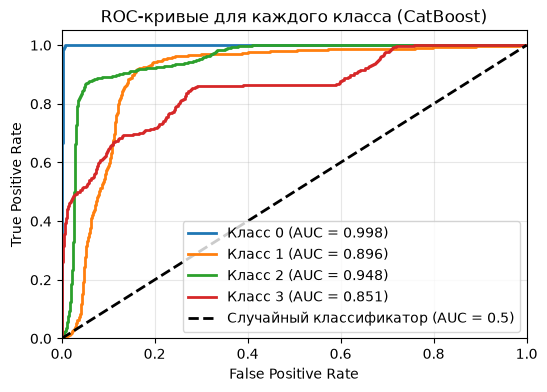

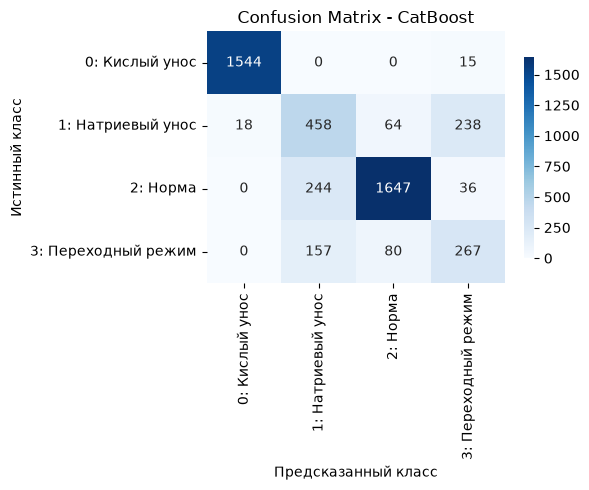


Итоги CV
  CatBoost        0.6404 ± 0.1674

  Победитель: CatBoost
CPU times: total: 3min
Wall time: 2min 25s


'CatBoost'

In [32]:
%%time
pipeline = ModelPipeline(
    X_train=features,
    y_train=target,
    groups=groups,
    n_splits=5,
    random_state=12345
)

pipeline.add_model(
    'XGBoost',
    XGBClassifier(random_state=12345,  eval_metric='mlogloss'), 
    param_dist=param_dist_xgb,
    need_sample_weight=True,
)

pipeline.add_model(
    'RandomForest',
    RandomForestClassifier(random_state=12345, n_jobs=-1),
    param_dist=param_dist_rf,
    need_sample_weight=True,
)

pipeline.add_model(
    'CatBoost',
    CatBoostClassifier(random_state=12345,   verbose=0), 
    param_dist=param_dist_cb,
    need_sample_weight=True,
)


pipeline.screen_models(n_iter=100, scoring='f1_macro', splitter='first_fold', verbose=True)
pipeline.cross_validate(metric='f1_macro')

## <a id="s4"></a> 4. Проверка лучшей модели


Топ-15 важнейших признаков для CatBoost:
               feature  importance
1           lba10cq201   59.520770
14   lba10cq201_std_4h   28.744617
12  lba10cq201_mean_2h    5.487824
6           lba10cf001    1.418941
2           had10cl001    1.282589
0           hal40cf001    0.967077
15  lba10cq201_delta_1    0.556219
16  lba10cq201_delta_2    0.407260
3           hah90ct001    0.404322
17  lba10cq201_delta_3    0.319586
4           hha10cp001    0.208164
18   lba10cq201__accel    0.167035
11             dow_cos    0.126416
13   lba10cq201_std_2h    0.124453
10             dow_sin    0.088987


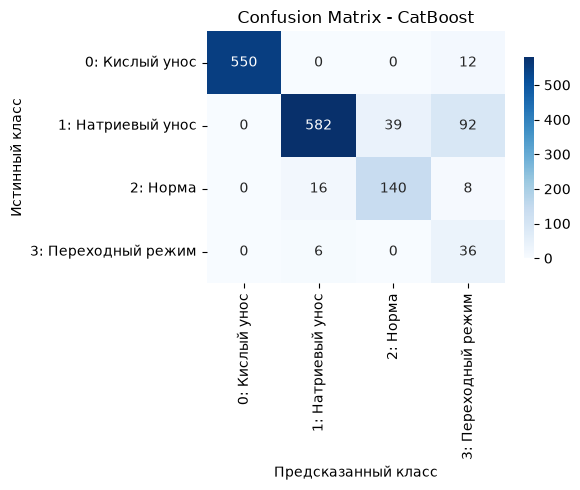

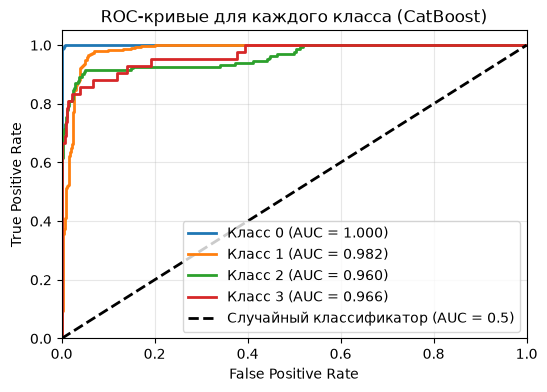


Финальная модель: CatBoost
  f1_macro: 0.7670773528494733
  f1_weighted: 0.9020237388338467
  roc_auc_ovr: 0.976917812141999


{'f1_macro': 0.7670773528494733,
 'f1_weighted': 0.9020237388338467,
 'roc_auc_ovr': 0.976917812141999}

In [33]:
pipeline.final_test(features, target, features_test, target_test)

## <a id="s5"></a> 5. Вывод

Целью проекта было создание модели, предсказывающей аварийный режим по водно-химическому режиму котла. Целевой признак получен разметкой на основе комбинированных экспертных правил (domain rules + statistical rules): 4 класса — «Кислый унос (хлоридный)», «Натриевый унос (щелочной)», «Норма», «Переходный режим». Автоматическая кластеризация k-means дала 3 группы, что не совпадает rule-based разметкой — это само по себе сигнал о возможной несогласованности разметки либо недостаточности данных.

В качестве кандидатов рассмотрены RandomForest, XGBoost, CatBoost. Метрика — f1_macro, так как она учитывает качество по каждому классу, включая редкие. Для экономии ресурсов подбор параметров проводился на части данных, финальная оценка — на 5-фолдовой GroupKFold.

**Результаты CV**: CatBoost 0.6404 ± 0.167, XGBoost 0.6290 ± 0.182, RF 0.6254 ± 0.169. Различия статистически незначимы при таком std. Выбор CatBoost — условный.

На тестовой выборке CatBoost показал **f1_macro=0.767, f1_weighted=0.902, roc_auc_ovr=0.977**. f1_macro выше CV-оценки не потому, что модель обобщает лучше, а потому что:

  - CV включает fold 1 с малой несбалансированной валидацией (3 класса, доминирует «Натриевый унос»), где f1_macro=0.404;

  - тестовая выборка более сбалансирована и содержит все 4 класса.

**По классам**: модель отлично различает «Кислый унос» (физически обосновано пороговой зависимостью от pH) и «Норму». Хуже всего — «Переходный режим» (~49.9%). Причины:

  - rule-based разметка — возможны несогласованные критерии;

  - Мало данных — 2.8% от выборки на тесте;

  - Физическая близость к соседним режимам.

**Ограничения оценки**:

  - Мало групп (8) — CV-оценка шумная;

  - На fold 1 roc_auc_ovr=nan — в валидации отсутствовал класс;

  - Различия между моделями — в пределах шума.

**Выводы и рекомендации:**

**Пересмотреть критерии разметки** с экспертом-химиком — приоритет №1. Низкое качество на «Переходном режиме» — это проблема данных, а не модели.

**Уменьшить дискретность** с 1 часа до 10–30 минут. Процессы развиваются за минуты, часовое усреднение размывает сигнал.

**Собрать больше данных** по «Переходному режиму» — 2.8% недостаточно.

**Использовать f1_weighted** как дополнительную метрику: 0.90 на тесте показывает, что модель практически пригодна для частых классов.

**Не менять модель** — все три равнозначны. Улучшение придёт от данных и разметки, а не от алгоритма.

**Внедрять можно** — при условии, что редкий класс не критичен или будет дообучен после исправления разметки.